# 8 - Robustez: os resultados mudam?

**Projeto final — SME0828 Introdução à Ciência de Dados**
Prof. Francisco A. Rodrigues — ICMC/USP

Grupo: _(nomes)_

<hr>

Um resultado só é confiável se **não depender de escolhas arbitrárias** da análise. Neste notebook verificamos se as conclusões principais se mantêm quando mudamos essas escolhas:

- **H1 (Etapa B):** comparando perfis iguais, o gênero **não** está associado à negação (OR = 1,005, p = 0,68);
- **H2 (Etapas D e E):** o modelo de crédito **sem** gênero nega 3,7 p.p. a mais as mulheres.

Fazemos quatro testes:

| Teste | Pergunta |
|---|---|
| **A. Variáveis omitidas** | Se incluirmos variáveis que deixamos de fora (raça, etnia, valor do empréstimo, casa pré-fabricada, bairro), o efeito do gênero muda? |
| **B. Subgrupos** | O resultado vale para todos os tipos de empréstimo, faixas de renda e regiões? |
| **C. Faltantes** | E se usarmos a base com faltantes preenchidos, em vez de apagá-los? |
| **D. Modelo de crédito** | Com as variáveis novas, o modelo fica melhor e menos desigual? |

A comparação com e sem efeito fixo de instituição (outro item da issue) já está no notebook 04: especificações (3), (4) e (5).

**O que não dá para testar:** o HMDA público não tem **credit score**, histórico de crédito nem patrimônio. Essas continuam sendo as principais limitações do trabalho.

### 1. Bibliotecas

In [1]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyfixest as pf

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")

SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)

BLUE   = "#2a78d6"
ORANGE = "#eb6834"
GRAY   = "#898781"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
os.makedirs("../figuras", exist_ok=True)
os.makedirs("../resultados", exist_ok=True)

### 2. Leitura e preparação dos dados

A preparação é **a mesma do notebook 04** (renda > 0, LTV winsorizado, estado e idade sem faltantes, *dummies* com as mesmas referências). Agora lemos também as variáveis que tinham ficado de fora.

In [2]:
colunas = ["lei", "state_code", "income", "combined_loan_to_value_ratio", "loan_type", "dti",
           "applicant_age", "negado", "mulher",
           # variáveis novas
           "derived_race", "derived_ethnicity", "loan_amount", "construction_method",
           "tract_minority_population_percent", "tract_to_msa_income_percentage"]

data = pd.read_parquet("../data/amostra_principal.parquet", columns=colunas)
data = data[data["income"] > 0]
limite_inf, limite_sup = data["combined_loan_to_value_ratio"].quantile([0.001, 0.999])
data["ltv"] = data["combined_loan_to_value_ratio"].clip(limite_inf, limite_sup)
data["log_renda"] = np.log(data["income"])
data = data.dropna(subset=["state_code", "applicant_age"]).reset_index(drop=True)

print("Dimensão:", data.shape)

Dimensão: (1532885, 17)


Variáveis de controle já usadas (iguais ao notebook 04):

In [3]:
nomes_dti = {"<20%": "ate20", "20%-<30%": "20a30", "30%-<36%": "30a36",
             "36%-<50%": "36a50", "50%-60%": "50a60", ">60%": "acima60"}
nomes_idade = {"25-34": "25a34", "<25": "menos25", "35-44": "35a44", "45-54": "45a54",
               "55-64": "55a64", "65-74": "65a74", ">74": "acima74"}

data["dti"] = pd.Categorical(data["dti"].astype(str).map(nomes_dti), categories=list(nomes_dti.values()))
data["idade"] = pd.Categorical(data["applicant_age"].map(nomes_idade), categories=list(nomes_idade.values()))
data["tipo"] = pd.Categorical(data["loan_type"], categories=["1", "2", "3", "4"])

dummies = pd.get_dummies(data[["dti", "tipo"]], drop_first=True).astype(int)
data = pd.concat([data, dummies], axis=1)
controles_dti = [c for c in dummies.columns if c.startswith("dti_")]
controles_tipo = [c for c in dummies.columns if c.startswith("tipo_")]

**Variáveis novas:**
- **raça e etnia**: *dummies*, com referência em "branca" e "não hispânica";
- **valor do empréstimo**: em log, como a renda;
- **casa pré-fabricada**: 1 se o imóvel é pré-fabricado (`construction_method` = 2);
- **bairro**: % de população de minorias no setor censitário e renda do setor em relação à média da região.

In [4]:
nomes_raca = {"White": "branca", "Black or African American": "negra", "Asian": "asiatica",
              "American Indian or Alaska Native": "indigena",
              "Native Hawaiian or Other Pacific Islander": "pacifico",
              "2 or more minority races": "duas_mais", "Race Not Available": "nao_informada",
              "Free Form Text Only": "outra", "Joint": "outra"}
nomes_etnia = {"Not Hispanic or Latino": "nao_hispanica", "Hispanic or Latino": "hispanica",
               "Ethnicity Not Available": "nao_informada", "Joint": "outra", "Free Form Text Only": "outra"}

data["raca"] = pd.Categorical(data["derived_race"].map(nomes_raca),
                              categories=["branca", "negra", "asiatica", "indigena", "pacifico", "duas_mais", "nao_informada", "outra"])
data["etnia"] = pd.Categorical(data["derived_ethnicity"].map(nomes_etnia),
                               categories=["nao_hispanica", "hispanica", "nao_informada", "outra"])
dummies_raca = pd.get_dummies(data[["raca", "etnia"]], drop_first=True).astype(int)
data = pd.concat([data, dummies_raca], axis=1)

data["log_valor"] = np.log(data["loan_amount"])
data["prefab"] = (data["construction_method"] == "2").astype(int)
data["pct_minoria_bairro"] = data["tract_minority_population_percent"]
data["renda_bairro"] = data["tract_to_msa_income_percentage"]

print("Dummies de raça e etnia:", list(dummies_raca.columns))
data[["log_valor", "prefab", "pct_minoria_bairro", "renda_bairro"]].describe().T.round(2)

Dummies de raça e etnia: ['raca_negra', 'raca_asiatica', 'raca_indigena', 'raca_pacifico', 'raca_duas_mais', 'raca_nao_informada', 'raca_outra', 'etnia_hispanica', 'etnia_nao_informada', 'etnia_outra']


,count,mean,std,min,25%,50%,75%,max
log_valor,1532885.0,12.56,0.62,8.52,12.18,12.56,12.91,17.96
prefab,1532885.0,0.04,0.20,0.00,0.00,0.00,0.00,1.00
pct_minoria_bairro,1532885.0,37.90,25.47,0.00,17.20,31.24,54.17,100.00
renda_bairro,1532885.0,107.42,39.92,0.00,82.00,103.00,127.00,516.00


Montamos as fórmulas. A especificação de referência é a **(5)** do notebook 04: controles de risco e efeitos fixos de instituição e estado.

In [5]:
base = " + ".join(["log_renda", "ltv"] + controles_dti + controles_tipo)
base_sem_tipo = " + ".join(["log_renda", "ltv"] + controles_dti)
raca_etnia = " + ".join(dummies_raca.columns)
emprestimo_bairro = "log_valor + prefab + pct_minoria_bairro + renda_bairro"
ef = "| lei + state_code"

print("Referência (5):", f"negado ~ mulher + {base} {ef}")

Referência (5): negado ~ mulher + log_renda + ltv + dti_20a30 + dti_30a36 + dti_36a50 + dti_50a60 + dti_acima60 + tipo_2 + tipo_3 + tipo_4 | lei + state_code


### 3. Teste A: variáveis omitidas

Se o efeito do gênero na especificação (5) estivesse "escondido" por alguma variável que deixamos de fora, ao incluí-la o coeficiente de `mulher` deveria **mudar**. Ajustamos quatro versões:

In [6]:
especificacoes_A = [
    ("A", "(5) Referência",                       f"negado ~ mulher + {base} {ef}", data),
    ("A", "A1: + raça e etnia",                   f"negado ~ mulher + {base} + {raca_etnia} {ef}", data),
    ("A", "A2: + valor, pré-fabricada e bairro",  f"negado ~ mulher + {base} + {emprestimo_bairro} {ef}", data),
    ("A", "A3: + todas as variáveis novas",       f"negado ~ mulher + {base} + {raca_etnia} + {emprestimo_bairro} {ef}", data),
]

resultados = []
for teste, nome, formula, dados in especificacoes_A:
    modelo = pf.feglm(formula, data=dados, family="logit", vcov={"CRV1": "lei"})
    ic_inf, ic_sup = modelo.confint().loc["mulher"]
    resultados.append({"Teste": teste, "Especificação": nome, "N": modelo._N,
                       "% mulheres": 100 * dados["mulher"].mean(),
                       "OR": np.exp(modelo.coef()["mulher"]), "OR IC inf": np.exp(ic_inf),
                       "OR IC sup": np.exp(ic_sup), "p-valor": modelo.pvalue()["mulher"]})
    print(f"{nome}: OR = {resultados[-1]['OR']:.3f}  p = {resultados[-1]['p-valor']:.3f}")

pd.DataFrame(resultados).round(3)

(5) Referência: OR = 1.005  p = 0.678


A1: + raça e etnia: OR = 0.963  p = 0.001


A2: + valor, pré-fabricada e bairro: OR = 0.999  p = 0.929


A3: + todas as variáveis novas: OR = 0.967  p = 0.003


,Teste,Especificação,N,% mulheres,OR,OR IC inf,OR IC sup,p-valor
0,A,(5) Referência,1514115,38.92,1.005,0.980,1.032,0.678
1,A,A1: + raça e etnia,1514115,38.92,0.963,0.942,0.985,0.001
2,A,"A2: + valor, pré-fabricada e bairro",1514115,38.92,0.999,0.973,1.025,0.929
3,A,A3: + todas as variáveis novas,1514115,38.92,0.967,0.945,0.988,0.003


Vamos olhar também os coeficientes das variáveis novas na versão A3, para entender o que elas acrescentam.

In [7]:
modelo_A3 = pf.feglm(especificacoes_A[3][2], data=data, family="logit", vcov={"CRV1": "lei"})
novas = list(dummies_raca.columns) + ["log_valor", "prefab", "pct_minoria_bairro", "renda_bairro"]
pd.DataFrame({"odds_ratio": np.exp(modelo_A3.coef()[novas]), "p-valor": modelo_A3.pvalue()[novas]}).round(3)

,odds_ratio,p-valor
Coefficient,,
raca_negra,1.866,0.000
raca_asiatica,1.303,0.000
raca_indigena,1.285,0.000
raca_pacifico,1.454,0.000
raca_duas_mais,1.680,0.000
raca_nao_informada,1.178,0.000
raca_outra,1.930,0.000
etnia_hispanica,1.254,0.000
etnia_nao_informada,1.200,0.000


### 4. Teste B: subgrupos

Repetimos a especificação (5) **separadamente** em diferentes grupos de pedidos. Se o efeito do gênero for nulo no total, mas forte num subgrupo, isso seria importante. Os grupos são:
- **tipo de empréstimo**: convencional, FHA e VA (o USDA tem poucos pedidos). Dentro de cada tipo, as *dummies* de tipo saem da fórmula;
- **faixa de renda**: terços da distribuição de renda;
- **região dos EUA**: as quatro regiões do censo americano. Os territórios (Porto Rico, Guam e Ilhas Virgens) ficam de fora.

In [8]:
regioes = {
    "Nordeste": ["CT", "ME", "MA", "NH", "RI", "VT", "NJ", "NY", "PA"],
    "Meio-Oeste": ["IL", "IN", "MI", "OH", "WI", "IA", "KS", "MN", "MO", "NE", "ND", "SD"],
    "Sul": ["DE", "FL", "GA", "MD", "NC", "SC", "VA", "DC", "WV", "AL", "KY", "MS", "TN", "AR", "LA", "OK", "TX"],
    "Oeste": ["AZ", "CO", "ID", "MT", "NV", "NM", "UT", "WY", "AK", "CA", "HI", "OR", "WA"],
}
data["regiao"] = "Territórios"
for regiao, estados in regioes.items():
    data.loc[data["state_code"].isin(estados), "regiao"] = regiao

data["faixa_renda"] = pd.qcut(data["income"], q=3, labels=["Renda baixa", "Renda média", "Renda alta"])

print(data["regiao"].value_counts())
print(data.groupby("faixa_renda", observed=True)["income"].agg(["min", "max"]))

regiao
Sul            722265
Meio-Oeste     344980
Oeste          266645
Nordeste       191209
Territórios      7786
Name: count, dtype: int64
               min       max
faixa_renda                 
Renda baixa    1.0      72.0
Renda média   73.0     116.0
Renda alta   117.0  535182.0


In [9]:
especificacoes_B = []
for tipo, nome in [("1", "Convencional"), ("2", "FHA"), ("3", "VA")]:
    especificacoes_B.append(("B", f"Tipo: {nome}", f"negado ~ mulher + {base_sem_tipo} {ef}", data[data["loan_type"] == tipo]))
for faixa in ["Renda baixa", "Renda média", "Renda alta"]:
    especificacoes_B.append(("B", faixa, f"negado ~ mulher + {base} {ef}", data[data["faixa_renda"] == faixa]))
for regiao in regioes:
    especificacoes_B.append(("B", f"Região: {regiao}", f"negado ~ mulher + {base} {ef}", data[data["regiao"] == regiao]))

for teste, nome, formula, dados in especificacoes_B:
    modelo = pf.feglm(formula, data=dados, family="logit", vcov={"CRV1": "lei"})
    ic_inf, ic_sup = modelo.confint().loc["mulher"]
    resultados.append({"Teste": teste, "Especificação": nome, "N": modelo._N,
                       "% mulheres": 100 * dados["mulher"].mean(),
                       "OR": np.exp(modelo.coef()["mulher"]), "OR IC inf": np.exp(ic_inf),
                       "OR IC sup": np.exp(ic_sup), "p-valor": modelo.pvalue()["mulher"]})
    print(f"{nome}: OR = {resultados[-1]['OR']:.3f}  p = {resultados[-1]['p-valor']:.3f}")

Tipo: Convencional: OR = 0.981  p = 0.271


Tipo: FHA: OR = 1.054  p = 0.003


Tipo: VA: OR = 1.088  p = 0.008


Renda baixa: OR = 0.974  p = 0.110


Renda média: OR = 0.999  p = 0.969


Renda alta: OR = 1.044  p = 0.006


Região: Nordeste: OR = 0.977  p = 0.308


Região: Meio-Oeste: OR = 0.987  p = 0.444


Região: Sul: OR = 1.029  p = 0.109


Região: Oeste: OR = 0.971  p = 0.079


### 5. Teste C: faltantes preenchidos

A base principal **apaga** os pedidos sem renda, DTI ou LTV. Vimos no notebook 02 que isso remove principalmente pedidos **negados** (o LTV falta em 39% deles). Agora usamos a **base alternativa**, em que:
- renda e LTV faltantes foram preenchidos com a mediana, com indicadores `renda_faltante` e `ltv_faltante`;
- o DTI faltante virou uma categoria própria.

Os indicadores entram como controles, para o modelo saber quais valores foram preenchidos.

In [10]:
alt = pd.read_parquet("../data/amostra_alternativa.parquet",
                      columns=["lei", "state_code", "income", "combined_loan_to_value_ratio", "loan_type", "dti",
                               "applicant_age", "negado", "mulher", "renda_faltante", "ltv_faltante"])
alt = alt[alt["income"] > 0]
lim_inf, lim_sup = alt["combined_loan_to_value_ratio"].quantile([0.001, 0.999])
alt["ltv"] = alt["combined_loan_to_value_ratio"].clip(lim_inf, lim_sup)
alt["log_renda"] = np.log(alt["income"])
alt = alt.dropna(subset=["state_code", "applicant_age"]).reset_index(drop=True)

nomes_dti_alt = dict(nomes_dti, Faltante="faltante")
alt["dti"] = pd.Categorical(alt["dti"].astype(str).map(nomes_dti_alt), categories=list(nomes_dti_alt.values()))
alt["tipo"] = pd.Categorical(alt["loan_type"], categories=["1", "2", "3", "4"])
alt = pd.concat([alt, pd.get_dummies(alt[["dti", "tipo"]], drop_first=True).astype(int)], axis=1)

print("Base principal:  ", len(data), f"pedidos, {data['negado'].mean():.1%} negados")
print("Base alternativa:", len(alt), f"pedidos, {alt['negado'].mean():.1%} negados")

formula_C = f"negado ~ mulher + {base} + dti_faltante + renda_faltante + ltv_faltante {ef}"
modelo = pf.feglm(formula_C, data=alt, family="logit", vcov={"CRV1": "lei"})
ic_inf, ic_sup = modelo.confint().loc["mulher"]
resultados.append({"Teste": "C", "Especificação": "C: base com faltantes preenchidos", "N": modelo._N,
                   "% mulheres": 100 * alt["mulher"].mean(),
                   "OR": np.exp(modelo.coef()["mulher"]), "OR IC inf": np.exp(ic_inf),
                   "OR IC sup": np.exp(ic_sup), "p-valor": modelo.pvalue()["mulher"]})
print(f"OR = {resultados[-1]['OR']:.3f}  p = {resultados[-1]['p-valor']:.3f}")

Base principal:   1532885 pedidos, 10.5% negados
Base alternativa: 1732741 pedidos, 15.3% negados


OR = 1.023  p = 0.223


### 6. Resumo dos testes A, B e C

Cada ponto é a odds ratio do gênero numa especificação, com o intervalo de 95%. Pontos **laranja** são estatisticamente significativos (p < 0,05). A linha tracejada (OR = 1) indica nenhuma diferença entre homens e mulheres.

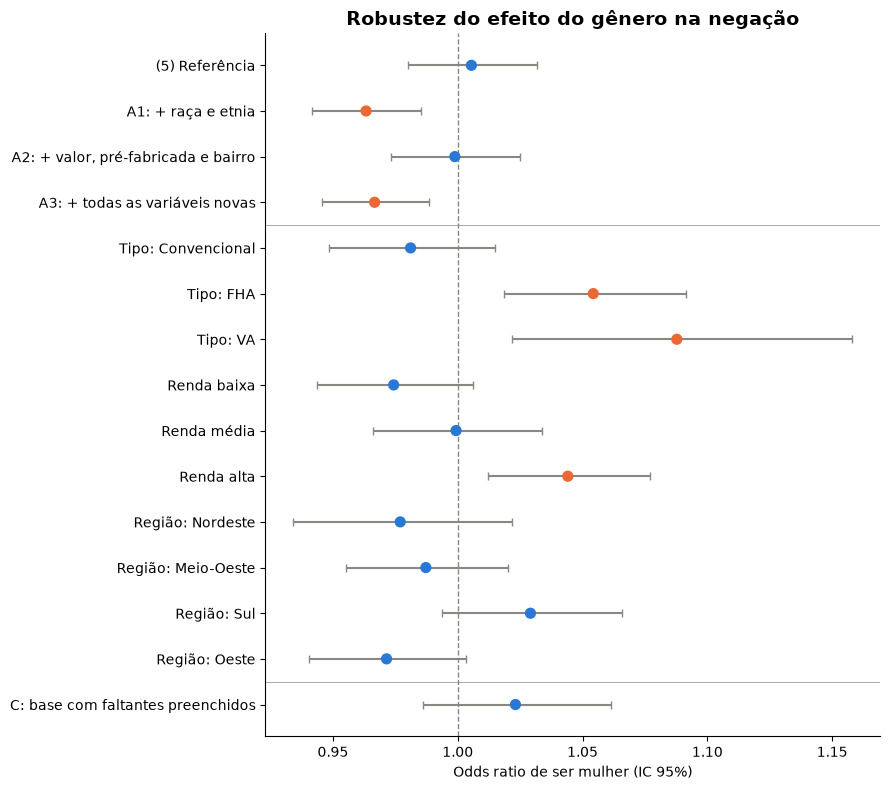

,Teste,Especificação,N,% mulheres,OR,OR IC inf,OR IC sup,p-valor
0,A,(5) Referência,1514115,38.920,1.005,0.980,1.032,0.678
1,A,A1: + raça e etnia,1514115,38.920,0.963,0.942,0.985,0.001
2,A,"A2: + valor, pré-fabricada e bairro",1514115,38.920,0.999,0.973,1.025,0.929
3,A,A3: + todas as variáveis novas,1514115,38.920,0.967,0.945,0.988,0.003
4,B,Tipo: Convencional,974007,40.136,0.981,0.948,1.015,0.271
5,B,Tipo: FHA,365697,43.811,1.054,1.019,1.091,0.003
6,B,Tipo: VA,139863,18.315,1.088,1.022,1.158,0.008
7,B,Renda baixa,508158,46.507,0.974,0.944,1.006,0.110
8,B,Renda média,493987,38.662,0.999,0.966,1.034,0.969
9,B,Renda alta,486073,31.399,1.044,1.012,1.077,0.006


In [11]:
tabela = pd.DataFrame(resultados)

fig, ax = plt.subplots(figsize=(9, 8))
y = np.arange(len(tabela))[::-1]
cores = [ORANGE if p < 0.05 else BLUE for p in tabela["p-valor"]]
ax.errorbar(tabela["OR"], y, xerr=[tabela["OR"] - tabela["OR IC inf"], tabela["OR IC sup"] - tabela["OR"]],
            fmt="none", ecolor=GRAY, capsize=3)
ax.scatter(tabela["OR"], y, color=cores, s=50, zorder=3)
ax.axvline(1, color=GRAY, linestyle="--", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(tabela["Especificação"])
for limite in [len(especificacoes_A), len(especificacoes_A) + len(especificacoes_B)]:
    ax.axhline(len(tabela) - limite - 0.5, color=GRAY, linewidth=0.5)
ax.set_xlabel("Odds ratio de ser mulher (IC 95%)")
ax.set_title("Robustez do efeito do gênero na negação", fontsize=14, fontweight="bold")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig("../figuras/robustez_odds_ratio.png", dpi=150)
plt.show()

tabela.round(3)

### 7. Teste D: o modelo de crédito com as variáveis novas

Por fim, voltamos ao **modelo de crédito** (Gradient Boosting sem gênero) do notebook 05. Treinamos duas versões, com o mesmo procedimento (mesma divisão treino/teste, mesmos hiperparâmetros e mesmo critério para o limiar):
- **original**: as variáveis do notebook 05;
- **ampliado**: + valor do empréstimo, casa pré-fabricada e as variáveis do bairro.

A **raça não entra** no modelo de crédito: assim como o gênero, ela é uma característica protegida e não pode ser usada para decidir crédito.

Comparamos o desempenho (AUC) e a diferença na taxa de negação prevista entre mulheres e homens. Leva alguns minutos.

In [12]:
data["state_cat"] = data["state_code"].astype("category")
atributos_original = ["log_renda", "ltv", "dti", "tipo", "state_cat", "idade"]
atributos_ampliado = atributos_original + ["log_valor", "prefab", "pct_minoria_bairro", "renda_bairro"]

estrato = data["negado"].astype(str) + "_" + data["mulher"].astype(str)
treino, teste = train_test_split(data, test_size=0.3, stratify=estrato, random_state=SEMENTE)
y_treino, y_teste = treino["negado"].values, teste["negado"].values
mulher = teste["mulher"].values == 1

comparacao = {}
for nome, atributos in [("Original", atributos_original), ("Ampliado", atributos_ampliado)]:
    modelo = HistGradientBoostingClassifier(categorical_features="from_dtype", learning_rate=0.05, max_leaf_nodes=15,
                                            max_iter=300, early_stopping=True, random_state=SEMENTE)
    proba_cv = cross_val_predict(modelo, treino[atributos], y_treino,
                                 cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE),
                                 method="predict_proba")[:, 1]
    limiar = np.quantile(proba_cv, 1 - y_treino.mean())
    modelo.fit(treino[atributos], y_treino)

    proba = modelo.predict_proba(teste[atributos])[:, 1]
    decisao = (proba >= limiar).astype(int)
    comparacao[nome] = {
        "AUC-ROC": roc_auc_score(y_teste, proba),
        "PR-AUC": average_precision_score(y_teste, proba),
        "Dif. nas probabilidades (p.p.)": 100 * (proba[mulher].mean() - proba[~mulher].mean()),
        "Dif. nas decisões (p.p.)": 100 * (decisao[mulher].mean() - decisao[~mulher].mean()),
    }
    print(nome, "ok")

comparacao["Bancos (real)"] = {"AUC-ROC": np.nan, "PR-AUC": np.nan,
                               "Dif. nas probabilidades (p.p.)": np.nan,
                               "Dif. nas decisões (p.p.)": 100 * (y_teste[mulher].mean() - y_teste[~mulher].mean())}
tabela_D = pd.DataFrame(comparacao).T
tabela_D.round(4)

Original ok


Ampliado ok


,AUC-ROC,PR-AUC,Dif. nas probabilidades (p.p.),Dif. nas decisões (p.p.)
Original,0.7867,0.5444,1.6462,3.6556
Ampliado,0.8084,0.5773,1.5792,3.0410
Bancos (real),NaN,NaN,NaN,1.4084


### 8. Salvando os resultados

In [13]:
tabela_md = tabela.copy()
tabela_md["OR (IC 95%)"] = tabela.apply(lambda r: f"{r['OR']:.3f} ({r['OR IC inf']:.3f}; {r['OR IC sup']:.3f})", axis=1)
tabela_md["p-valor"] = tabela["p-valor"].map(lambda p: "<0,001" if p < 0.001 else f"{p:.3f}")
tabela_md = tabela_md[["Teste", "Especificação", "N", "% mulheres", "OR (IC 95%)", "p-valor"]].round(1)

with open("../resultados/robustez.md", "w", encoding="utf-8") as f:
    f.write("## Testes A, B e C: odds ratio do gênero (especificação 5 e variações)\n\n")
    f.write(tabela_md.to_markdown(index=False))
    f.write("\n\n## Teste D: modelo de crédito sem gênero com variáveis novas\n\n")
    f.write(tabela_D.round(4).to_markdown())
    f.write("\n")
tabela_md

,Teste,Especificação,N,% mulheres,OR (IC 95%),p-valor
0,A,(5) Referência,1514115,38.9,1.005 (0.980; 1.032),0.678
1,A,A1: + raça e etnia,1514115,38.9,0.963 (0.942; 0.985),0.001
2,A,"A2: + valor, pré-fabricada e bairro",1514115,38.9,0.999 (0.973; 1.025),0.929
3,A,A3: + todas as variáveis novas,1514115,38.9,0.967 (0.945; 0.988),0.003
4,B,Tipo: Convencional,974007,40.1,0.981 (0.948; 1.015),0.271
5,B,Tipo: FHA,365697,43.8,1.054 (1.019; 1.091),0.003
6,B,Tipo: VA,139863,18.3,1.088 (1.022; 1.158),0.008
7,B,Renda baixa,508158,46.5,0.974 (0.944; 1.006),0.110
8,B,Renda média,493987,38.7,0.999 (0.966; 1.034),0.969
9,B,Renda alta,486073,31.4,1.044 (1.012; 1.077),0.006


### Conclusão

**A conclusão principal da H1 se mantém:** em nenhum teste aparece uma desvantagem **geral** das mulheres. Mas os testes revelam nuances importantes.

**Teste A: variáveis omitidas**
- Incluir **valor do empréstimo, casa pré-fabricada e bairro** (A2) **não muda nada**: OR = 0,999 (p = 0,93).
- Incluir **raça e etnia** (A1) **inverte o sinal**: OR = 0,963 (IC 95%: 0,942 a 0,985; p = 0,001). Ou seja, comparando homens e mulheres da **mesma raça**, com o mesmo perfil, no mesmo banco e estado, as mulheres têm chances **ligeiramente menores** (cerca de 4%) de negação.
- A explicação: solicitantes negros têm chance de negação 87% maior que brancos (OR = 1,87), e há proporcionalmente quase o dobro de mulheres negras entre as solicitantes (16% contra 9% entre os homens). Sem o controle de raça, parte dessa desvantagem racial aparecia como se fosse de gênero, compensando uma pequena vantagem feminina.

**Teste B: subgrupos**
- No empréstimo **convencional** (64% da amostra), em todas as regiões e nas rendas baixa e média, **não há diferença significativa**.
- Há diferenças **contra as mulheres** em três subgrupos: **FHA** (OR = 1,054; p = 0,003), **VA** (OR = 1,088; p = 0,008) e **renda alta** (OR = 1,044; p = 0,006).
- **Cuidado com comparações múltiplas:** fizemos 10 testes de subgrupo. Com α = 0,05, é esperado que algum dê significativo **por acaso**. Usando a correção de Bonferroni (α = 0,05 / 10 = 0,005), apenas o **FHA** continua significativo. Esses resultados são **exploratórios** e indicam onde vale investigar mais, não conclusões firmes.

**Teste C: faltantes preenchidos**
- Usando a base com faltantes preenchidos (taxa de negação de 15,3%, contra 10,5% na base principal), a OR é 1,023 (p = 0,22): **continua não significativa**. A exclusão dos casos incompletos não muda a conclusão.

**Teste D: modelo de crédito ampliado**
- As variáveis novas **melhoram o modelo**: a AUC sobe de 0,787 para **0,808**.
- A diferença nas decisões entre mulheres e homens **cai** de 3,66 para **3,04 p.p.**, mas continua **mais que o dobro** da dos bancos (1,41 p.p.). A diferença nas probabilidades fica praticamente igual (1,58 p.p.), então o limiar continua amplificando a desigualdade. **A conclusão da H2 se mantém.**

**Resumo:** os resultados principais são **robustos**. Os bancos não prejudicam as mulheres em geral para perfis iguais (e, controlando raça, até as favorecem levemente). O modelo de crédito continua mais desigual que os bancos mesmo com mais variáveis. Os subgrupos FHA e VA merecem atenção em estudos futuros, idealmente com dados de credit score, que o HMDA público não tem.